# Evaluating Holiday and Weather Inputs for Traffic Forecasting

This notebook runs the same scripts as the terminal workflow. Compare A (calendar + past counts), B (A + whole-day holiday) and C (B + previous-hour weather), with fixed model settings and identical target hours.

This notebook is a guided execution interface. The recorded results and models are supplied so you can inspect them before rerunning training.


## 1. Load the project

Run this notebook inside the extracted `traffic_project` directory, or upload the full `CV7001_Traffic_Project.zip` when prompted in Google Colab. The notebook alone does not contain the dataset or model files.


In [2]:
from pathlib import Path
import os, sys, json, csv, html, zipfile, subprocess
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if not Path('feature_study.py').exists():
    if (Path.cwd() / 'traffic_project/feature_study.py').exists():
        os.chdir(Path.cwd() / 'traffic_project')
    elif IN_COLAB:
        uploaded = files.upload()
        name = next((name for name in uploaded if name.lower().endswith('.zip')), None)
        if name is None:
            raise ValueError('Upload the complete traffic project ZIP.')
        destination = Path('/content/cv7001_traffic')
        destination.mkdir(exist_ok=True)
        with zipfile.ZipFile(name) as archive:
            for member in archive.namelist():
                if not (destination / member).resolve().is_relative_to(destination.resolve()):
                    raise ValueError('Unexpected archive path')
            archive.extractall(destination)
        os.chdir(next(destination.rglob('feature_study.py')).parent)
    else:
        raise RuntimeError('Open the notebook from the extracted traffic_project folder.')
PROJECT = Path.cwd()
print('Working directory:', PROJECT)
def run(*args):
    subprocess.run([sys.executable, *map(str, args)], check=True)


Working directory: c:\Users\Cynthia\Downloads\CV7001_Traffic_Project\traffic_project


## 2. Install the dependencies

Each training/prediction command below launches a fresh Python process. The notebook itself displays saved CSV and PNG outputs. Python 3.11 or 3.12 can be used with the provided dependencies. The experiment was run using Python 3.11.9. Training uses CPUs, and a GPU runtime is unnecessary.


In [5]:
run('-m', 'pip', 'install', '-r', 'requirements.txt')


## 3. Inspect the inputs and timing

For a 09:00-10:00 forecast made at 09:00, use completed 08:00-09:00 measurements. A holiday indicator is known from the calendar. Actual 09:00-10:00 weather is not yet available and is excluded. The original holiday names mark midnight only, so we construct a whole-day calendar flag.


In [7]:
from IPython.display import display, HTML, Image as DisplayImage

def show_csv(path, limit=12, columns=None):
    with open(path, encoding='utf-8', newline='') as stream:
        rows = list(csv.DictReader(stream))[:limit]
    if not rows:
        return
    columns = columns or list(rows[0])
    table = '<table><tr>' + ''.join('<th>' + html.escape(key) + '</th>' for key in columns) + '</tr>'
    table += ''.join('<tr>' + ''.join('<td>' + html.escape(str(row[key])) + '</td>' for key in columns) + '</tr>' for row in rows)
    display(HTML(table + '</table>'))

show_csv('results/feature_inputs.csv', limit=5,
         columns=['date_time', 'weather_observed_at', 'volume_lag_1h', 'is_holiday', 'temperature_c_lag_1h', 'rain_mm_lag_1h'])
print(Path('examples/context_inputs.json').read_text())


date_time,weather_observed_at,volume_lag_1h,is_holiday,temperature_c_lag_1h,rain_mm_lag_1h
2012-10-09 09:00:00,2012-10-09 08:00:00,5765.0,0,5.230000000000018,0.0
2012-10-09 10:00:00,2012-10-09 09:00:00,5599.0,0,6.2000000000000455,0.0
2012-10-09 11:00:00,2012-10-09 10:00:00,4534.0,0,8.220000000000027,0.0
2012-10-09 12:00:00,2012-10-09 11:00:00,4691.0,0,9.960000000000036,0.0
2012-10-09 13:00:00,2012-10-09 12:00:00,5067.0,0,10.930000000000007,0.0


[
  {
    "date_time": "2018-01-01 08:00:00",
    "volume_lag_1h": 677.0,
    "volume_lag_24h": 1319.0,
    "volume_lag_168h": 1260.0,
    "previous_hour_weather": {
      "date_time": "2018-01-01 07:00:00",
      "temperature_c": -25.389999999999986,
      "rain_mm": 0.0,
      "snow_mm": 0.0,
      "cloud_cover_percent": 1.0,
      "conditions": [
        "Clear"
      ]
    }
  },
  {
    "date_time": "2018-08-24 03:00:00",
    "volume_lag_1h": 387.0,
    "volume_lag_24h": 381.0,
    "volume_lag_168h": 408.0,
    "previous_hour_weather": {
      "date_time": "2018-08-24 02:00:00",
      "temperature_c": 20.510000000000048,
      "rain_mm": 1.02,
      "snow_mm": 0.0,
      "cloud_cover_percent": 90.0,
      "conditions": [
        "Rain",
        "Thunderstorm"
      ]
    }
  },
  {
    "date_time": "2018-01-02 08:00:00",
    "volume_lag_1h": 5696.0,
    "volume_lag_24h": 811.0,
    "volume_lag_168h": 2982.0,
    "previous_hour_weather": {
      "date_time": "2018-01-02 07:00:00",


## 4. Read the supplied reference results

The three versions use 150 trees, maximum depth 18, minimum leaf size 2 and seed 42. The only planned change is the feature set. The 2018 period had already been evaluated in the earlier baseline; this is a fixed follow-up held out from fitting, not a newly blind test.


variant,split,mae,rmse,r2,n
A,validation,162.59174730164978,257.6659348584039,0.983077334139801,8603
A,test,151.38730792194318,241.1476461106649,0.9849797561618912,6485
B,validation,162.32394037247886,257.47151724631135,0.983102861946234,8603
B,test,150.85331058183627,240.53909575497667,0.9850554694561059,6485
C,validation,161.63202636260212,257.68970660061507,0.9830742114933604,8603
C,test,151.36277603625555,240.8228660185241,0.9850201877497624,6485


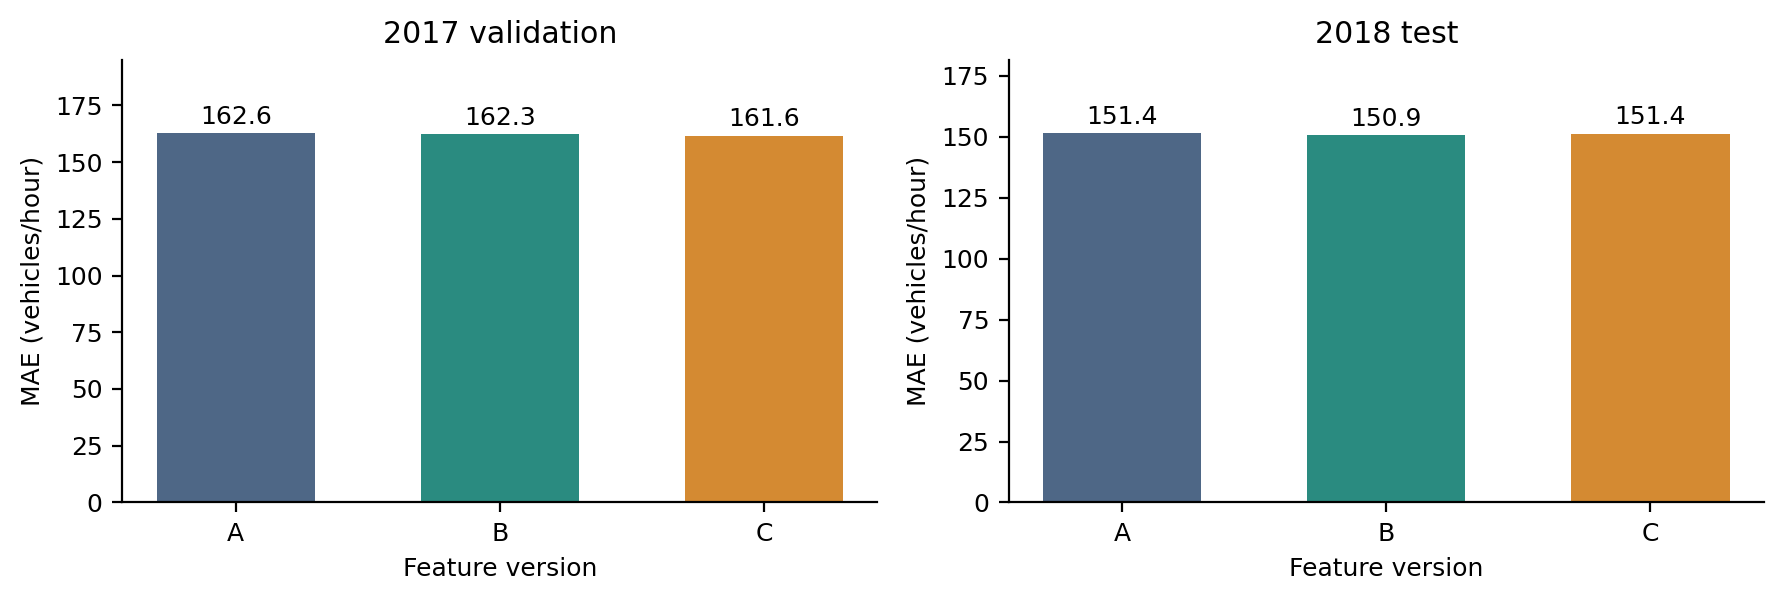

group,variant,mae,rmse,r2,n
All hours,A,151.38730792194318,241.1476461106649,0.9849797561618912,6485
All hours,B,150.85331058183627,240.53909575497667,0.9850554694561059,6485
All hours,C,151.36277603625555,240.8228660185241,0.9850201877497624,6485
Holiday,A,185.94123062226907,259.14650422644905,0.972237059194866,166
Holiday,B,176.60083387416117,245.8512626889406,0.9750126819988328,166
Holiday,C,180.07152859382958,244.80366494505807,0.9752251754141601,166
Previous-hour precipitation,A,133.04420520361006,193.10645323420948,0.9903293511401107,400
Previous-hour precipitation,B,130.81012704613147,190.05363370883146,0.9906327007450463,400
Previous-hour precipitation,C,130.97037243464334,188.6256589149789,0.9907729350087193,400


In [8]:
show_csv('results/feature_metrics.csv')
display(DisplayImage(filename='results/feature_comparison.png', width=850))
show_csv('results/subgroup_metrics.csv')


## 5. Rerun training

**This cell executes fitting and updates the working models/results.** It fits each version before 2017, compares validation MAE in 2017, records the selected version, then refits through 2017 and predicts the 2018 period. The test scores do not choose the default model. All three model files are saved.

If you only want to inspect the supplied results and run prediction, skip this training cell. The original downloaded ZIP remains your reference copy.


In [5]:
run('feature_study.py', 'train')


## 6. Verify the executed results

Checks cover identical target hours, reproduction of baseline A, prior-hour weather, whole-day holidays, fitting-only imputation, score calculations and JSON inference consistency.


In [8]:
run('verify.py')
show_csv('results/feature_metrics.csv')
print('Validation-selected model:', json.loads(Path('models/selection.json').read_text()))


variant,split,mae,rmse,r2,n
A,validation,162.59174730164978,257.6659348584039,0.983077334139801,8603
A,test,151.38730792194318,241.1476461106649,0.9849797561618912,6485
B,validation,162.32394037247886,257.47151724631135,0.983102861946234,8603
B,test,150.85331058183627,240.53909575497667,0.9850554694561059,6485
C,validation,161.63202636260212,257.68970660061507,0.9830742114933604,8603
C,test,151.36277603625555,240.8228660185241,0.9850201877497624,6485


Validation-selected model: {'selected': 'C', 'criterion': 'lowest 2017 validation MAE'}


## 7. Read the figures

The figures are plotted from actual scores and predictions. The holiday example uses a date selected in advance. Subgroups overlap, and positive recorded precipitation is not a complete classification of all rainy/snowy conditions. Green/orange image-box annotations from the separate road-damage project are unrelated to these traffic graphs.


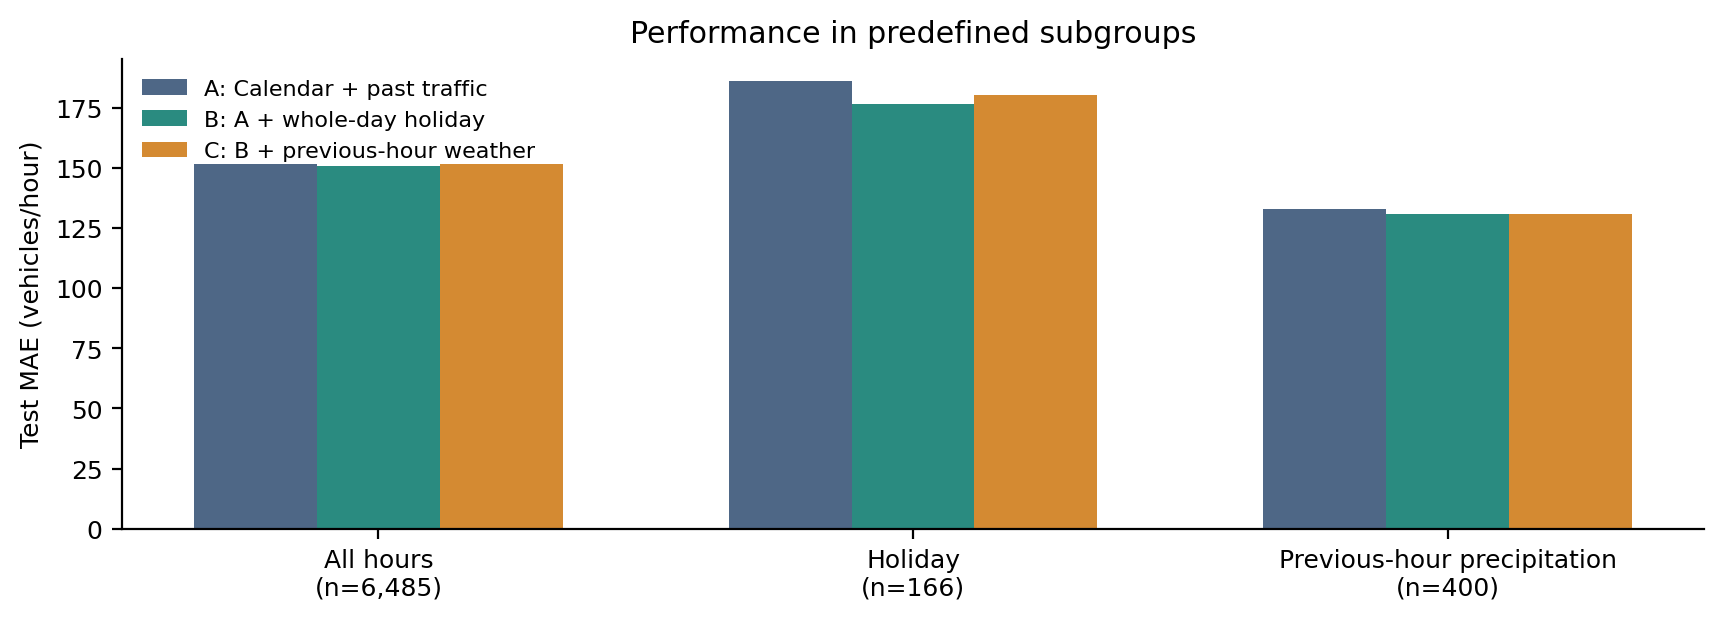

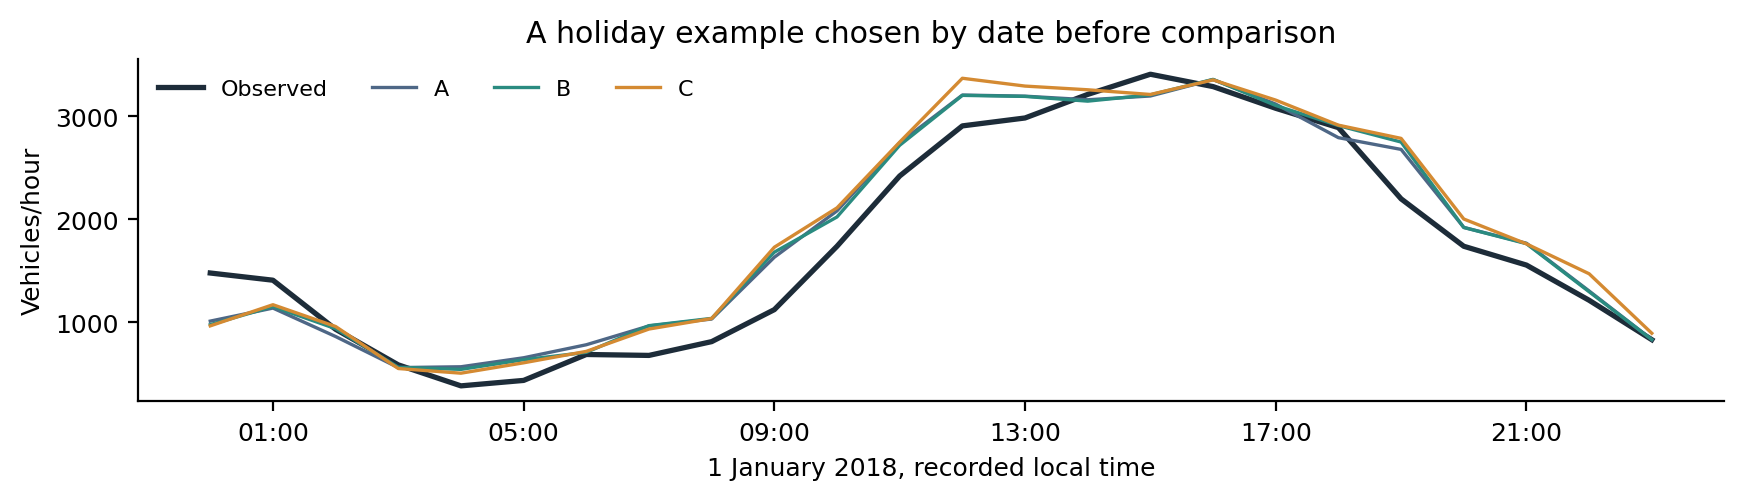

In [10]:
display(DisplayImage(filename='results/context_errors.png', width=850))
display(DisplayImage(filename='results/holiday_example.png', width=850))


## 8. Run prediction without retraining

The provided JSON examples contain actual historical inputs but no target labels. `selected` follows validation MAE; A, B or C can also be requested explicitly. C requires the previous-hour weather object. For a new input, copy and edit the JSON according to README, using real available history.


In [10]:
run('feature_study.py', 'predict', '--variant', 'selected', '--inputs', 'examples/context_inputs.json')
run('feature_study.py', 'predict', '--variant', 'B', '--inputs', 'examples/context_inputs.json')
run('feature_study.py', 'predict', '--variant', 'C', '--inputs', 'examples/context_inputs.json')


## 9. Download your results

Run this cell after training, verification and prediction to download `My_Traffic_Forecast_Results.zip`. It contains the trained models, evaluation tables, plots, example predictions and project code. Keep the supplied full project ZIP for the original dataset and baseline reference outputs.


In [11]:
output = PROJECT.parent / 'My_Traffic_Forecast_Results.zip'
excluded_folders = {'.venv', '__pycache__', '.ipynb_checkpoints', '.git', 'baseline_archive', 'data'}
with zipfile.ZipFile(output, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in PROJECT.rglob('*'):
        if not path.is_file():
            continue
        relative = path.relative_to(PROJECT)
        if any(part in excluded_folders for part in relative.parts):
            continue
        if path.suffix == '.pyc':
            continue
        archive.write(path, Path('traffic_project') / relative)
print(output)
if IN_COLAB:
    files.download(str(output))


c:\Users\Cynthia\Downloads\CV7001_Traffic_Project\My_Traffic_Forecast_Results.zip
